# Streams, Redirection & Pipes

The power of the shell comes from small programs that do one job well and that you can connect. Every program reads from **standard input** and writes to **standard output** and **standard error**. **Redirection** connects these streams to files; **pipes** connect one program's output to the next program's input.

**After this lesson you can:**

1. Explain the three standard streams and their file descriptors.
2. Redirect output and errors with `>`, `>>`, `2>`, `2>&1`, `<`.
3. Build pipelines with `|`, `tee` and `xargs`.
4. Check exit codes and make pipelines fail safely with `set -o pipefail`.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

WORK = Path(tempfile.mkdtemp())          # a folder on the Linux file system (not on a Windows drive)
REPO = Path.cwd().parent                 # the course repository: real data for some examples

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def sh(cmd: str, cwd: Path = WORK, quiet: bool = False, check: bool = False) -> Output:
    """Run a command with bash, print the command and its output."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True)
    shorten = lambda t: t.replace(str(WORK), "<work>").replace(str(REPO), "<repo>")
    out = shorten((r.stdout + r.stderr).rstrip())
    if not quiet:
        print(f"$ {shorten(cmd)}" + (f"\n{out}" if out else ""))
    if check and r.returncode:
        raise RuntimeError(f"command failed with exit code {r.returncode}")
    return Output(r.stdout)

## 1. The Three Standard Streams

| Stream | File descriptor | Default | Use |
| :--- | :-: | :--- | :--- |
| standard input (stdin) | 0 | keyboard | data in |
| standard output (stdout) | 1 | terminal | results |
| standard error (stderr) | 2 | terminal | messages and errors |

Results go to stdout and messages to stderr, so you can save the results without the messages.

| Operator | Meaning |
| :--- | :--- |
| `cmd > file` | write stdout to a file (replace) |
| `cmd >> file` | append stdout to a file |
| `cmd 2> file` | write stderr to a file |
| `cmd > file 2>&1` | write stdout and stderr to the same file |
| `cmd < file` | read stdin from a file |
| `cmd > /dev/null` | discard the output |

In [2]:
sh("ls /etc/hostname /does/not/exist")                     # both streams on the terminal
sh("ls /etc/hostname /does/not/exist > out.txt 2> err.txt; echo '--- out:'; cat out.txt; echo '--- err:'; cat err.txt")
sh("ls /etc/hostname /does/not/exist > all.txt 2>&1; cat all.txt")
sh("echo 'first run' > run.log && echo 'second run' >> run.log && cat run.log")
sh("wc -l < run.log")
sh("ls /does/not/exist 2> /dev/null; echo \"exit code: $?\"")

$ ls /etc/hostname /does/not/exist
/etc/hostname
ls: cannot access '/does/not/exist': No such file or directory
$ ls /etc/hostname /does/not/exist > out.txt 2> err.txt; echo '--- out:'; cat out.txt; echo '--- err:'; cat err.txt
--- out:
/etc/hostname
--- err:
ls: cannot access '/does/not/exist': No such file or directory
$ ls /etc/hostname /does/not/exist > all.txt 2>&1; cat all.txt
ls: cannot access '/does/not/exist': No such file or directory
/etc/hostname
$ echo 'first run' > run.log && echo 'second run' >> run.log && cat run.log
first run
second run
$ wc -l < run.log
2
$ ls /does/not/exist 2> /dev/null; echo "exit code: $?"
exit code: 2


## 2. Pipes

`cmd1 | cmd2` sends the stdout of `cmd1` to the stdin of `cmd2`. Both programs run at the same time, and data flows through a small buffer, so a pipeline can process files that are much larger than memory.

The classic "word frequency" pipeline uses only standard tools. It runs on the **real README of this course**.

In [3]:
pipeline = (f"cat {REPO}/README.md "
            "| tr -cs 'A-Za-z' '\\n' "          # split into one word per line
            "| tr 'A-Z' 'a-z' "                 # lower case
            "| grep -vxE '.{1,3}' "             # drop words with 1-3 letters
            "| sort | uniq -c | sort -rn | head -12")
top_words = sh(pipeline)

$ cat <repo>/README.md | tr -cs 'A-Za-z' '\n' | tr 'A-Z' 'a-z' | grep -vxE '.{1,3}' | sort | uniq -c | sort -rn | head -12
     45 readme
     45 planned
     45 engineer
     38 data
     26 learning
     22 optional
     21 module
     20 python
     18 roles
     18 paths
     15 this
     15 modules


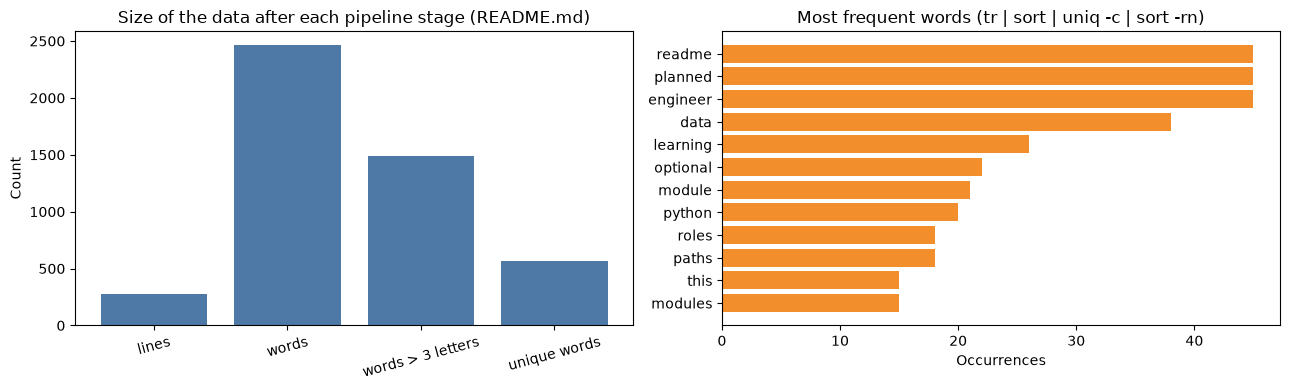

{'lines': 274, 'words': 2462, 'words > 3 letters': 1487, 'unique words': 564}


In [4]:
import matplotlib.pyplot as plt

stages = {
    "lines": f"wc -l < {REPO}/README.md",
    "words": f"tr -cs 'A-Za-z' '\\n' < {REPO}/README.md | wc -l",
    "words > 3 letters": f"tr -cs 'A-Za-z' '\\n' < {REPO}/README.md | grep -vxE '.{{0,3}}' | wc -l",
    "unique words": f"tr -cs 'A-Za-z' '\\n' < {REPO}/README.md | tr 'A-Z' 'a-z' | grep -vxE '.{{0,3}}' | sort -u | wc -l",
}
counts = {name: int(sh(cmd, quiet=True)) for name, cmd in stages.items()}
pairs = [l.split() for l in top_words.splitlines()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(counts.keys(), counts.values(), color="#4E79A7")
ax1.set(title="Size of the data after each pipeline stage (README.md)", ylabel="Count")
ax1.tick_params(axis="x", rotation=15)
ax2.barh([w for _, w in pairs][::-1], [int(c) for c, _ in pairs][::-1], color="#F28E2B")
ax2.set(title="Most frequent words (tr | sort | uniq -c | sort -rn)", xlabel="Occurrences")
plt.tight_layout()
plt.show()
print(counts)

## 3. `tee` and `xargs`

- `tee file` writes its input to a file **and** to stdout, so you can save an intermediate result and continue the pipeline.
- `xargs cmd` turns input lines into **arguments** of a command. `-0` together with `find -print0` handles file names with spaces safely; `-P 4` runs four processes in parallel.

In [5]:
for i in range(1, 6):
    (WORK / f"report {i}.csv").write_text("id,value\n" + "\n".join(f"{j},{j * i}" for j in range(100 * i)) + "\n")
sh("ls *.csv | tee files.txt | wc -l && cat files.txt")
sh("find . -name '*.csv' -print0 | xargs -0 wc -l | sort -n")
sh("find . -name '*.csv' -print0 | xargs -0 -P 4 -I{} gzip -k {} && ls *.gz | wc -l")

$ ls *.csv | tee files.txt | wc -l && cat files.txt
5
report 1.csv
report 2.csv
report 3.csv
report 4.csv
report 5.csv
$ find . -name '*.csv' -print0 | xargs -0 wc -l | sort -n
  101 ./report 1.csv
  201 ./report 2.csv
  301 ./report 3.csv
  401 ./report 4.csv
  501 ./report 5.csv
 1505 total
$ find . -name '*.csv' -print0 | xargs -0 -P 4 -I{} gzip -k {} && ls *.gz | wc -l
5


## 4. Exit Codes and Safe Pipelines

Every command returns an **exit code**: `0` means success, any other value means failure. `$?` holds the exit code of the last command.

- `cmd1 && cmd2` runs `cmd2` only if `cmd1` succeeded.
- `cmd1 || cmd2` runs `cmd2` only if `cmd1` failed.
- A pipeline returns the exit code of its **last** command, so an early failure is hidden. `set -o pipefail` makes the pipeline fail if any command fails.

In [6]:
sh("grep -q 'id,value' 'report 1.csv' && echo 'header found' || echo 'header missing'")
sh("cat missing.csv | wc -l; echo \"exit code without pipefail: $?\"")
sh("set -o pipefail; cat missing.csv | wc -l; echo \"exit code with pipefail: $?\"")

$ grep -q 'id,value' 'report 1.csv' && echo 'header found' || echo 'header missing'
header found
$ cat missing.csv | wc -l; echo "exit code without pipefail: $?"
0
exit code without pipefail: 0
cat: missing.csv: No such file or directory
$ set -o pipefail; cat missing.csv | wc -l; echo "exit code with pipefail: $?"
0
exit code with pipefail: 1
cat: missing.csv: No such file or directory


Without `pipefail`, the pipeline reports success (exit code 0) although `cat` failed: `wc -l` printed 0 and succeeded. In scripts, always start with `set -euo pipefail` (Lesson 06).

## 5. Here-Documents and Process Substitution

- A **here-document** (`<<'EOF' ... EOF`) passes several lines as stdin, for example a configuration file or a SQL script.
- **Process substitution** (`<(cmd)`) lets a command read another command's output as if it were a file.

In [7]:
sh("""cat > config.ini <<'EOF'
[model]
name = gbm
max_depth = 6
EOF
cat config.ini""")
sh("diff <(ls *.csv) <(ls *.gz | sed 's/.gz$//') && echo 'every CSV has a .gz copy'")

$ cat > config.ini <<'EOF'
[model]
name = gbm
max_depth = 6
EOF
cat config.ini
[model]
name = gbm
max_depth = 6
$ diff <(ls *.csv) <(ls *.gz | sed 's/.gz$//') && echo 'every CSV has a .gz copy'
every CSV has a .gz copy


*Insight: Design scripts and command-line tools to read stdin and write results to stdout, with messages on stderr and a meaningful exit code. Then they combine with every other tool through pipes, and failures stay visible.*

## Real-World Use Case or Analogy

A pipeline is like an **assembly line in a factory**. Each station (program) does one job: cut, paint, pack. The conveyor belt (the pipe) carries each part to the next station as soon as it is ready, so the stations work at the same time. Defective parts go to a separate bin (stderr), not into the boxes for customers (stdout).

Engineers use one-line pipelines every day: find the most frequent errors in a log (`grep ERROR app.log | cut -d' ' -f5 | sort | uniq -c | sort -rn | head`), count rows in hundreds of files, or compress thousands of files in parallel with `xargs -P`.